In [6]:
with open("mylife.txt", "w", encoding="utf-8") as f:
  f.write("Hello, this is mtlife.txt")

print("mylife.txt 파일이 정상적으로 생성되었습니다.")

mylife.txt 파일이 정상적으로 생성되었습니다.


In [7]:
f = open("mylife.txt", "r", encoding="utf-8")

In [9]:
f.read()

'Hello, this is mtlife.txt'

In [10]:
f.read()

''

In [8]:
%whos

Variable    Type             Data/Info
--------------------------------------
f           TextIOWrapper    <_io.TextIOWrapper name='<...>ode='r' encoding='utf-8'>
file_name   str              myfile.txt
os          module           <module 'os' (frozen)>


<class 'bytes'>
2152 바이트
b'\xff\xd8\xff\xe0'
True
복사 완료: 2152 바이트


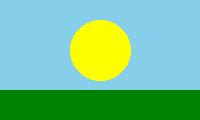

In [16]:
import os
from PIL import Image, ImageDraw

file_path = "myfile.jpg"

# 1. 이미지 만들기 (파일이 없을 때만)
if not os.path.exists(file_path):
    img = Image.new("RGB", (200, 120), "skyblue")
    draw = ImageDraw.Draw(img)
    draw.ellipse((70, 20, 130, 80), fill="yellow")   # 노란 원
    draw.rectangle((0, 90, 200, 120), fill="green")  # 초록 땅
    img.save(file_path, "JPEG")

# 2. 바이너리 모드로 읽기
with open(file_path, "rb") as f:
    data = f.read()

print(type(data))                    # <class 'bytes'>
print(len(data), "바이트")
print(data[:4])                      # b'\xff\xd8\xff\xe0' (JPG 시작 부분)
print(data[:2] == b"\xff\xd8")      # True면 JPG 맞음

# 3. 바이너리 모드로 복사하기
with open(file_path, "rb") as src, open("copy.jpg", "wb") as dst:
    while chunk := src.read(8192):
        dst.write(chunk)

print("복사 완료:", os.path.getsize("copy.jpg"), "바이트")

# 4. 화면에 이미지 표시
from IPython.display import Image as IPyImage, display
display(IPyImage(data=data))

In [17]:
import os

file_path = "myfile.jpg"

if os.path.exists(file_path):
    with open(file_path, "rb") as f:
        data = f.read()          # 파일 전체를 bytes로 읽음

    print(type(data))            # <class 'bytes'>
    print(len(data), "바이트")
    print(data[:4])              # b'\xff\xd8\xff\xe0' (JPG 시작 부분)
else:
    print(f"'{file_path}' 파일이 존재하지 않습니다. 먼저 코랩 환경에 이미지 파일을 업로드해 주세요.")

<class 'bytes'>
2152 바이트
b'\xff\xd8\xff\xe0'


In [18]:
!pip install faker -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 21.2 MB/s eta 0:00:00


In [19]:
import csv
from faker import Faker

fake = Faker("ko_KR")
Faker.seed(42)   # 실행할 때마다 같은 데이터가 나오게 고정

with open("users.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["name", "email", "age", "city"])
    for _ in range(20):
        writer.writerow([
            fake.name(),
            fake.unique.email(),
            fake.random_int(min=18, max=65),
            fake.city(),
        ])

print("users.csv 생성 완료")

users.csv 생성 완료


In [20]:
import sqlite3

conn = sqlite3.connect("practice.db")
cur = conn.cursor()

cur.execute("DROP TABLE IF EXISTS users")
cur.execute("""
    CREATE TABLE users (
        id    INTEGER PRIMARY KEY AUTOINCREMENT,
        name  TEXT NOT NULL,
        email TEXT UNIQUE NOT NULL,
        age   INTEGER,
        city  TEXT
    )
""")

with open("users.csv", newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    rows = [(r["name"], r["email"], int(r["age"]), r["city"]) for r in reader]

cur.executemany(
    "INSERT INTO users (name, email, age, city) VALUES (?, ?, ?, ?)", rows
)
conn.commit()
print(f"{cur.rowcount}건 저장 완료")

20건 저장 완료


In [21]:
def show(title, rows):
    print(f"\n--- {title} ---")
    for row in rows:
        print(row)

# C (Create): 데이터 추가
cur.execute(
    "INSERT INTO users (name, email, age, city) VALUES (?, ?, ?, ?)",
    ("홍길동", "gildong@example.com", 30, "서울"),
)
conn.commit()
new_id = cur.lastrowid
print("추가된 id:", new_id)

# R (Read): 조회
cur.execute("SELECT * FROM users LIMIT 5")
show("전체 중 5건", cur.fetchall())

cur.execute("SELECT * FROM users WHERE id = ?", (new_id,))
show("방금 추가한 데이터", cur.fetchall())

cur.execute("SELECT * FROM users WHERE age >= 40 ORDER BY age DESC")
show("40세 이상 (나이 내림차순)", cur.fetchall())

# U (Update): 수정
cur.execute("UPDATE users SET age = ?, city = ? WHERE id = ?", (31, "부산", new_id))
conn.commit()
print("\n수정된 행 수:", cur.rowcount)

cur.execute("SELECT * FROM users WHERE id = ?", (new_id,))
show("수정 후", cur.fetchall())

# D (Delete): 삭제
cur.execute("DELETE FROM users WHERE id = ?", (new_id,))
conn.commit()
print("\n삭제된 행 수:", cur.rowcount)

cur.execute("SELECT COUNT(*) FROM users")
print("남은 데이터 수:", cur.fetchone()[0])

추가된 id: 21

--- 전체 중 5건 ---
(1, '김수민', 'seongmingim@example.net', 52, '안양시 만안구')
(2, '김미숙', 'migyeonggim@example.org', 63, '예산군')
(3, '이예원', 'eunju02@example.net', 45, '가평군')
(4, '김정훈', 'gimsangceol@example.com', 56, '시흥시')
(5, '서옥자', 'sgim@example.net', 57, '포천시')

--- 방금 추가한 데이터 ---
(21, '홍길동', 'gildong@example.com', 30, '서울')

--- 40세 이상 (나이 내림차순) ---
(10, '박중수', 'igim@example.org', 65, '공주시')
(2, '김미숙', 'migyeonggim@example.org', 63, '예산군')
(9, '김경희', 'junho13@example.net', 63, '용인시 기흥구')
(7, '윤성호', 'jeonghun41@example.net', 58, '안산시')
(5, '서옥자', 'sgim@example.net', 57, '포천시')
(4, '김정훈', 'gimsangceol@example.com', 56, '시흥시')
(1, '김수민', 'seongmingim@example.net', 52, '안양시 만안구')
(17, '김영호', 'gimgyeonghyi@example.org', 52, '단양군')
(11, '신영자', 'ii@example.net', 49, '안양시 만안구')
(19, '한정희', 'pji@example.com', 46, '인제군')
(3, '이예원', 'eunju02@example.net', 45, '가평군')
(12, '고민서', 'eunyeongi@example.org', 42, '수원시 장안구')
(16, '박지영', 'coemyeongsug@example.org', 41, '용인시 처인구')

수정된 행 수: 1

--- 수정 

In [22]:
conn.close()

In [23]:
!pip install faker -q

In [24]:
import csv
import sqlite3
from faker import Faker

fake = Faker("ko_KR")
Faker.seed(42)

# 1. CSV 100건 생성
with open("users.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["name", "email", "age", "city"])
    for _ in range(100):
        writer.writerow([
            fake.name(),
            fake.unique.email(),
            fake.random_int(min=18, max=65),
            fake.city(),
        ])

# 2. DB 저장
conn = sqlite3.connect("practice.db")
cur = conn.cursor()

cur.execute("DROP TABLE IF EXISTS users")
cur.execute("""
    CREATE TABLE users (
        id    INTEGER PRIMARY KEY AUTOINCREMENT,
        name  TEXT NOT NULL,
        email TEXT UNIQUE NOT NULL,
        age   INTEGER,
        city  TEXT
    )
""")

with open("users.csv", newline="", encoding="utf-8") as f:
    rows = [(r["name"], r["email"], int(r["age"]), r["city"])
            for r in csv.DictReader(f)]

cur.executemany(
    "INSERT INTO users (name, email, age, city) VALUES (?, ?, ?, ?)", rows
)
conn.commit()

# 3. 확인
cur.execute("SELECT COUNT(*) FROM users")
print("저장된 데이터 수:", cur.fetchone()[0])

cur.execute("SELECT * FROM users LIMIT 5")
for row in cur.fetchall():
    print(row)

conn.close()

저장된 데이터 수: 100
(1, '김수민', 'seongmingim@example.net', 52, '안양시 만안구')
(2, '김미숙', 'migyeonggim@example.org', 63, '예산군')
(3, '이예원', 'eunju02@example.net', 45, '가평군')
(4, '김정훈', 'gimsangceol@example.com', 56, '시흥시')
(5, '서옥자', 'sgim@example.net', 57, '포천시')


In [28]:
import sqlite3

# 1. DB 연결 (파일이 없으면 새로 만들어짐)
conn = sqlite3.connect("example.db")
cur = conn.cursor()

# 2. 테이블 만들기
cur.execute("""
    CREATE TABLE IF NOT EXISTS users (
        id   INTEGER PRIMARY KEY AUTOINCREMENT,
        name TEXT,
        age  INTEGER
    )
""")

# 3. Create: 데이터 추가
cur.execute("INSERT INTO users (name, age) VALUES (?, ?)", ("홍길동", 25))
conn.commit()

# 4. Read: 조회
cur.execute("SELECT * FROM users")
print(cur.fetchall())

# 5. Update: 수정
cur.execute("UPDATE users SET age = ? WHERE name = ?", (26, "홍길동"))
conn.commit()

# 6. Delete: 삭제
cur.execute("DELETE FROM users WHERE name = ?", ("홍길동",))
conn.commit()

# 7. 연결 닫기 (오타를 close()로 수정했습니다)
conn.close()

[(2, '홍길동', 25)]


In [35]:
import sqlite3

conn = sqlite3.connect("example.db")

with conn:
    cur = conn.cursor()

    # 테이블 만들기 (매번 새로 시작하도록 삭제 후 생성)
    cur.execute("DROP TABLE IF EXISTS users")
    cur.execute("""
        CREATE TABLE users (
            id   INTEGER PRIMARY KEY AUTOINCREMENT,
            name TEXT NOT NULL,
            age  INTEGER
        )
    """)

    # C (Create): 추가
    cur.execute("INSERT INTO users (name, age) VALUES (?, ?)", ("홍길동", 25))
    cur.executemany(
        "INSERT INTO users (name, age) VALUES (?, ?)",
        [("김철수", 30), ("이영희", 28)],
    )
    print("[Create 후]")
    cur.execute("SELECT * FROM users")
    print(cur.fetchall())

    # R (Read): 조회
    cur.execute("SELECT * FROM users WHERE age >= ?", (28,))
    print("\n[Read: 28세 이상]")
    print(cur.fetchall())

    cur.execute("SELECT * FROM users WHERE name = ?", ("홍길동",))
    print("\n[Read: 홍길동 한 명]")
    print(cur.fetchone())

    # U (Update): 수정
    cur.execute("UPDATE users SET age = ? WHERE name = ?", (26, "홍길동"))
    print("\n[Update 후]")
    cur.execute("SELECT * FROM users")
    print(cur.fetchall())

    # D (Delete): 삭제
    cur.execute("DELETE FROM users WHERE name = ?", ("이영희",))
    print("\n[Delete 후]")
    cur.execute("SELECT * FROM users")
    print(cur.fetchall())

conn.close()

[Create 후]
[(1, '홍길동', 25), (2, '김철수', 30), (3, '이영희', 28)]

[Read: 28세 이상]
[(2, '김철수', 30), (3, '이영희', 28)]

[Read: 홍길동 한 명]
(1, '홍길동', 25)

[Update 후]
[(1, '홍길동', 26), (2, '김철수', 30), (3, '이영희', 28)]

[Delete 후]
[(1, '홍길동', 26), (2, '김철수', 30)]


In [38]:
import requests

r = requests.get('https://api.github.com/user', auth=('user', 'pass'))
r

<Response [401]>

In [40]:
import requests

In [41]:
r.content

b'{"message":"Requires authentication","documentation_url":"https://docs.github.com/rest/users/users#get-the-authenticated-user","status":"401"}'

REST API

In [ ]:
'''
{
  "args": {},
  "headers": {
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7",
    "Accept-Encoding": "gzip, deflate",
    "Accept-Language": "ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7",
    "Host": "httpbin.org",
    "Upgrade-Insecure-Requests": "1",
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36",
    "X-Amzn-Trace-Id": "Root=1-64d6350b-4d8c7710021da0ab4ccabacc"
  },
  "origin": "112.169.221.81",
  "url": "http://httpbin.org/get"
}
'''

'\n{\n  "args": {},\n  "headers": {\n    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7",\n    "Accept-Encoding": "gzip, deflate",\n    "Accept-Language": "ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7",\n    "Host": "httpbin.org",\n    "Upgrade-Insecure-Requests": "1",\n    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36",\n    "X-Amzn-Trace-Id": "Root=1-64d6350b-4d8c7710021da0ab4ccabacc"\n  },\n  "origin": "112.169.221.81",\n  "url": "http://httpbin.org/get"\n}\n'

In [ ]:
import requests
r = requests.get('https://httpbin.org/')
print(r)


<Response [200]>


In [ ]:
# header & body
print(r.text)

<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <title>httpbin.org</title>
    <link href="https://fonts.googleapis.com/css?family=Open+Sans:400,700|Source+Code+Pro:300,600|Titillium+Web:400,600,700"
        rel="stylesheet">
    <link rel="stylesheet" type="text/css" href="/flasgger_static/swagger-ui.css">
    <link rel="icon" type="image/png" href="/static/favicon.ico" sizes="64x64 32x32 16x16" />
    <style>
        html {
            box-sizing: border-box;
            overflow: -moz-scrollbars-vertical;
            overflow-y: scroll;
        }

        *,
        *:before,
        *:after {
            box-sizing: inherit;
        }

        body {
            margin: 0;
            background: #fafafa;
        }
    </style>
</head>

<body>
    <a href="https://github.com/requests/httpbin" class="github-corner" aria-label="View source on Github">
        <svg width="80" height="80" viewBox="0 0 250 250" style="fill:#151513; color:#fff; position: absolute;